In [2]:
import os
import scipy.stats as stats
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.api as sm
import matplotlib.ticker as ticker
import matplotlib.dates as mpldates
import seaborn as sns
from Regression_utils import *


In [3]:
main_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)


Index(['Unnamed: 0.1', 'Unnamed: 0', 'Name', 'Year-Month', 'Hours',
       'Water Total', 'PSI', 'Revenue', 'Metered DM', 'Power Factor',
       'Billed DM', 'Billing KWH', 'Fuel Rate', 'Electrical Bill',
       'Workover Info', 'Workover Cost', 'Pump Model', 'Pump Number',
       'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'Workover Count', 'Disposal Rate',
       'KWH per Barrel', 'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       '6 Month Avg KWH', '6 Month Avg Revenue', '6 Month Avg Income',
       '6 Month Avg Total Cost', '6 Month Avg Electrical Cost',
       '6 Month Avg Maintenance Cost', '6 Month Avg Workover Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Mon

Name
ABNEY #2        0
ABNEY #3        1
ALBERTSON #4    1
BASS #4         0
BASS #5         2
               ..
WILLIAMS #6     3
WILLIAMS #7     0
WILLIAMS #8     1
WILLIAMS #9     3
WILSON #4       2
Name: Workover Count, Length: 87, dtype: int64
42
87


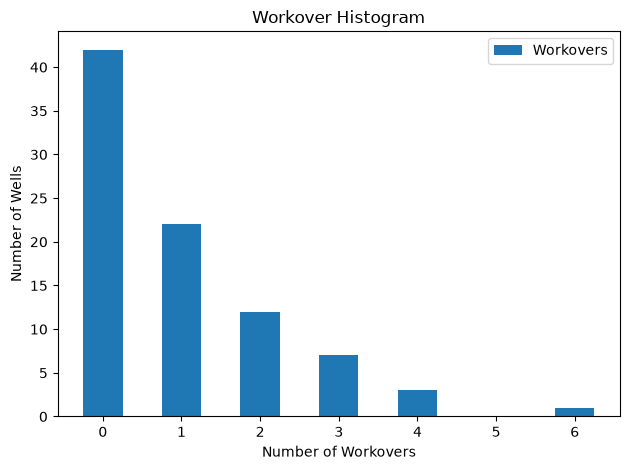

,Unnamed: 0.1,Unnamed: 0,Name,Year-Month,Hours,Water Total,PSI,Revenue,Metered DM,Power Factor,...,6 Month Avg Revenue per Barrel,6 Month Avg Income per Barrel,Cumulative Electrical Cost,Cumulative Workover Cost,Cumulative Maintenance Cost,Cumulative Total Cost,Cumulative Income,Cumulative Revenue,Date,Period
0,0,0,ABNEY #2,2017-08,759.127859,503920,772.857143,18566.216116,194.4,88.2,...,NaN,NaN,5973.24,0.00,0.00,5973.24,12592.976116,18566.216116,2017-08-01,2017-08
1,1,1,ABNEY #2,2017-09,781.635656,518861,777.142857,20320.151624,194.4,88.2,...,NaN,NaN,12106.93,0.00,0.00,12106.93,26779.437740,38886.367740,2017-09-01,2017-09
2,2,2,ABNEY #2,2017-10,795.296101,527929,782.857143,20470.111597,196.8,88.1,...,NaN,NaN,18971.25,0.00,0.00,18971.25,40385.229337,59356.479337,2017-10-01,2017-10
3,3,3,ABNEY #2,2017-11,759.219752,503981,774.285714,20120.328465,197.6,87.8,...,NaN,NaN,25155.16,0.00,0.00,25155.16,54321.647801,79476.807801,2017-11-01,2017-11
4,4,4,ABNEY #2,2017-12,717.051338,475989,773.333333,19138.079039,192.0,87.6,...,NaN,NaN,31217.85,0.00,0.00,31217.85,67397.036841,98614.886841,2017-12-01,2017-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9391,9391,9391,WILSON #4,2026-03,0.000000,0,0.000000,0.000000,0.1,31.7,...,0.0,-933.386667,203746.50,101898.61,13771.57,319416.68,92012.238184,411428.918184,2026-03-01,2026-03
9392,9392,9392,WILSON #4,2026-04,0.000000,0,0.000000,0.000000,0.0,24.2,...,0.0,-933.205000,204679.16,101898.61,13771.57,320349.34,91079.578184,411428.918184,2026-04-01,2026-04
9393,9393,9393,WILSON #4,2026-05,0.000000,0,0.000000,0.000000,0.0,24.2,...,0.0,-933.226667,205613.05,101898.61,13771.57,321283.23,90145.688184,411428.918184,2026-05-01,2026-05
9394,9394,9394,WILSON #4,2026-06,0.000000,0,0.000000,NaN,0.0,24.2,...,NaN,NaN,206546.94,101898.61,13771.57,322217.12,NaN,NaN,2026-06-01,2026-06


In [4]:
main_df["Workover Count"] = np.where(
    main_df["Workover Cost"] > 1, 
    1, 
    0
)

main_df["Disposal Rate"] = np.where(
    main_df["Hours"] > 0,
    main_df["Water Total"] / main_df["Hours"],
    0
)
# matplotlib doesn't like the pure string values for Year-Month
main_df["Date"] = pd.to_datetime(main_df["Year-Month"])
main_df["Period"] = pd.to_datetime(main_df["Year-Month"]).dt.to_period(freq="M")
#print(main_df["Period"])

#main_df["Year-Month"] = main_df["Year-Month"].dt.to_period("M")

# Get a count of workovers for each well
print(main_df.groupby("Name")["Workover Count"].sum())
workover_counts = main_df.groupby("Name")["Workover Count"].sum()
no_workover = workover_counts[(workover_counts < 1)]
print(len(no_workover))
print(len(workover_counts))
fig, ax = plt.subplots()

max_val = int(max(workover_counts))
bins = range(0, max_val + 2)
ax.hist(workover_counts, bins=bins, align="left", rwidth = 0.5)

ax.set_title("Workover Histogram")
ax.legend(["Workovers"])
ax.set_xlabel("Number of Workovers")
ax.set_ylabel("Number of Wells")
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.xaxis.set_major_locator(ticker.MultipleLocator(1.0))
plt.tight_layout()
plt.show()


#example global variable
TOTAL_WORKOVER_COST = main_df["Workover Cost"].sum()

main_df.dropna(subset = ["Billing KWH", "Electrical Cost per Barrel", "Metered DM"])


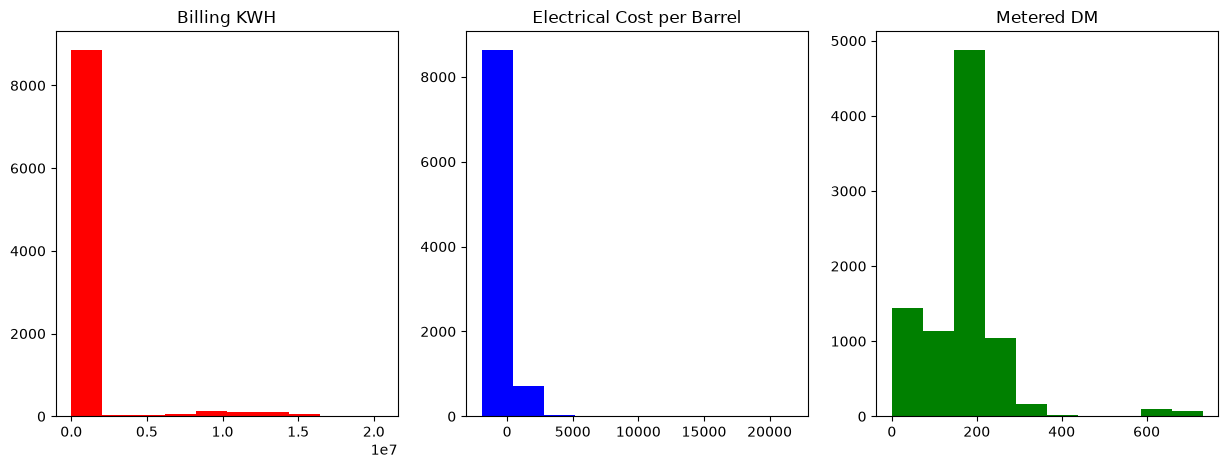

In [5]:
fig, axs = plt.subplots(1, 3, figsize = (15, 5))

axs[0].hist(main_df["Billing KWH"], color="red")
axs[0].set_title("Billing KWH")

axs[1].hist(main_df["Electrical Cost per Barrel"], color="blue")
axs[1].set_title("Electrical Cost per Barrel")

axs[2].hist(main_df["Metered DM"], color="green")
axs[2].set_title("Metered DM")

plt.show()

In [12]:
#transforming the data to achieve normal distribution
main_df["Transformed Billing KWH"] = np.sqrt(main_df["Billing KWH"])
main_df["Transformed Electrical Cost per Barrel"] = np.sqrt(main_df["Electrical Cost per Barrel"])
main_df["Transformed Metered DM"] = np.sqrt(main_df["Metered DM"])

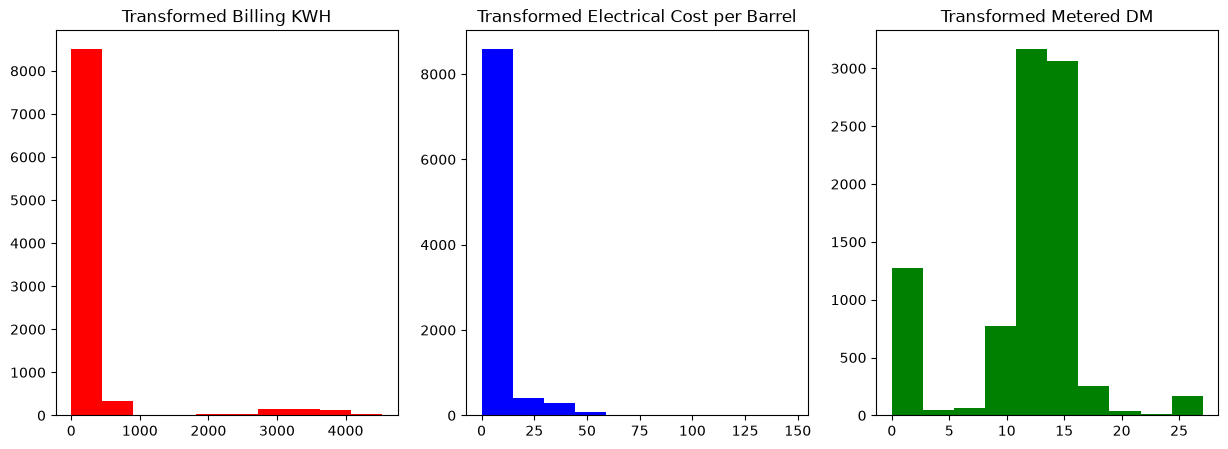

In [13]:

fig, axs = plt.subplots(1, 3, figsize = (15, 5))

axs[0].hist(main_df["Transformed Billing KWH"], color="red")
axs[0].set_title("Transformed Billing KWH")

axs[1].hist(main_df["Transformed Electrical Cost per Barrel"], color="blue")
axs[1].set_title("Transformed Electrical Cost per Barrel")

axs[2].hist(main_df["Transformed Metered DM"], color="green")
axs[2].set_title("Transformed Metered DM")

plt.show()

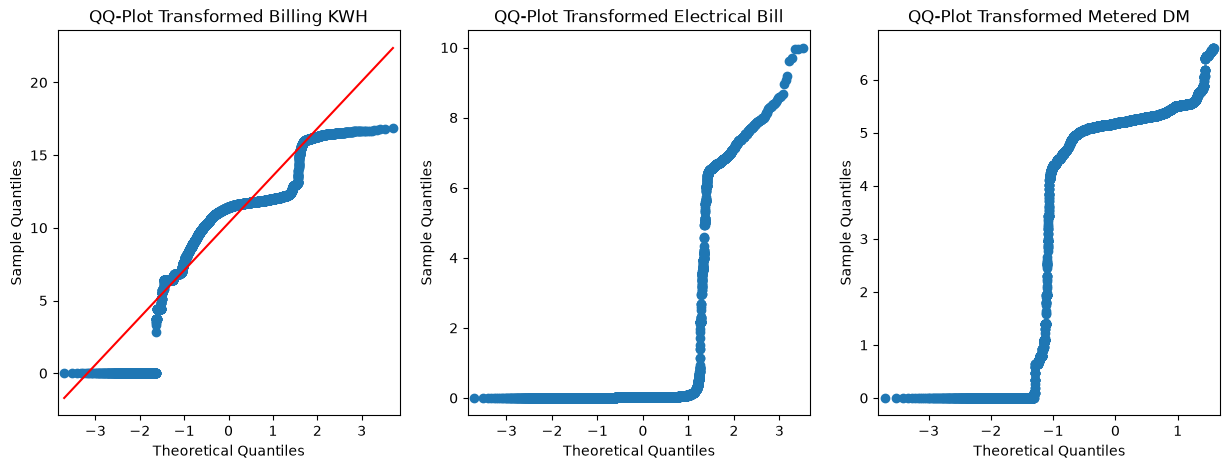

In [11]:
# QQ-plots
fig, axs = plt.subplots(1, 3, figsize = (15, 5))

sm.qqplot(main_df["Transformed Billing KWH"], line = "s", ax=axs[0])
axs[0].set_title("QQ-Plot Transformed Billing KWH")

sm.qqplot(main_df["Transformed Electrical Cost per Barrel"], line = "s", ax=axs[1])
axs[1].set_title("QQ-Plot Transformed Electrical Bill")

sm.qqplot(main_df["Transformed Metered DM"], line = "s", ax=axs[2])
axs[2].set_title("QQ-Plot Transformed Metered DM")

plt.tight_layout
plt.show()


In [66]:
#Date Processing
# Filtering the data to between pre and post workover.
#KWH_filt = KWH_df.drop((KWH_df["Workover Count"] > 0) & (KWH_df["Workover Count"] <2))
#KWH_filt.tail()
main_df["First Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["First Workover Date"] = main_df["First Workover Date"].dt.to_period("M")
main_df["Second Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["Second Workover Date"] = main_df["Second Workover Date"].dt.to_period("M")

wells = main_df["Name"].unique()
#print(wells)
#Assigning workover dates to each well
for well in wells:
    well_filt = main_df["Name"] == well
    work_filt = main_df["Workover Count"] == 1
    full_filt = (well_filt) & (work_filt)
    
    # filter example -> main_df[full_filt]["Year-Month"]
    if len(main_df[full_filt]) == 1:
        main_df.loc[full_filt, "First Workover Date"] = main_df[full_filt]["Year-Month"]
        print(well, " 1")
        print(main_df[full_filt]["First Workover Date"])
        
    elif len(main_df[full_filt]) > 1:
        # first date = first workover date
        # second date = second workover date
        first_date = main_df.loc[full_filt, "Year-Month"].iloc[0]
        second_date = main_df.loc[full_filt, "Year-Month"].iloc[1]

        main_df.loc[full_filt, "First Workover Date"] = first_date
        main_df.loc[full_filt, "Second Workover Date"] = second_date
        
        print(well, "> 1")
        print(main_df[full_filt]["First Workover Date"])
        print(main_df.loc[full_filt, "Second Workover Date"])

ABNEY #3  1
203    2025-07
Name: First Workover Date, dtype: period[M]
ALBERTSON #4  1
275    2022-07
Name: First Workover Date, dtype: period[M]
BASS #5 > 1
457    2019-09
534    2019-09
Name: First Workover Date, dtype: period[M]
457    2026-02
534    2026-02
Name: Second Workover Date, dtype: period[M]
BLUM #7  1
1374    2024-02
Name: First Workover Date, dtype: period[M]
BOLDRICK #1 > 1
1512    2017-08
1540    2017-08
Name: First Workover Date, dtype: period[M]
1512    2019-12
1540    2019-12
Name: Second Workover Date, dtype: period[M]
BOLDRICK #2 > 1
1636    2018-12
1668    2018-12
Name: First Workover Date, dtype: period[M]
1636    2021-08
1668    2021-08
Name: Second Workover Date, dtype: period[M]
BOLES #1  1
1944    2017-08
Name: First Workover Date, dtype: period[M]
CHRISTIAN #1  1
2154    2026-02
Name: First Workover Date, dtype: period[M]
COLVILLE #4 > 1
2434    2022-06
2481    2022-06
Name: First Workover Date, dtype: period[M]
2434    2026-05
2481    2026-05
Name: Second

In [60]:
#Paired t-test for the wells with 1 workover
# attrs is a list of column names
# TODO: implement (ttest_workovers(attrs: list[str], month_count, workover_number))
def ttest_workovers(attrs: list[str], in_df, month_count:int = 6, workover_number:int = 1) -> pd.DataFrame:
    """ Conducts a t-test on both each individual well and all wells for the provided attributes. 
    Attrs is a list of column names from the dataframe of interest. Month count is the number of months 
    to be used in selecting rows before and after a workover. Workover number indicates which (first, second)
    workover we are looking for. 

    returns pd.DataFrame
    """
    rows = []
    # adjust workover number to allow for indexing to start at 1 for easier interpretation
    workover_pos = workover_number - 1

    # dataframes designed to show values 6 months before and after workovers for all wells
    total_before_df = pd.DataFrame()
    total_after_df = pd.DataFrame()

    
    # Paired T-test for first workover date
    for well in wells:
        # Filter to this well
        well_filt = in_df["Name"] == well
    
        # ascending sort oldest to newest records
        well_df = in_df[well_filt].sort_values("Year-Month").reset_index(drop=True)
    
        # Find the row(s) where Year-Month matches the workover date
        workover_rows = well_df[well_df["Workover Count"] == 1]
    
        if workover_rows.empty:
            # No matching workover date found for this well — skip
            continue

        try:
            # Get the integer position of the workover month
            workover_idx = workover_rows.index[0]
            workover_idx = workover_rows.index[workover_pos]
            
            # Slice month_count months before (not including workover month)
            if (workover_idx - month_count) >= 0:
                before_df = well_df.iloc[(workover_idx - month_count):workover_idx]
            else:
                print(f"Not enough months before workover available for {well}")
                continue
        
            # Slice month_count months after (not including workover month)
            if (workover_idx + month_count) < len(well_df):
                after_df = well_df.iloc[workover_idx + 1: workover_idx + month_count + 1]
            else:
                print(f"Not enough months after workover available for {well}")
                continue
                
               # Only keep this well if it has enough months on both sides
            if len(before_df) == month_count and len(after_df) == month_count:
                # concatenate the months before and after workover for each well into a single dataframe
                total_before_df = pd.concat([total_before_df, before_df])
                total_after_df = pd.concat([total_after_df, after_df])
                
                for attr in attrs:
                    before = before_df[attr].to_numpy()
                    after = after_df[attr].to_numpy()
                    
                    #if length of n is less than 2, the T-test will throw and error
                    if len(before) < 2:
                        t_stat, p_value = np.nan, np.nan
                    else: 
                        result = stats.ttest_rel(before, after)
                        t_stat, p_value = result.statistic, result.pvalue
                        
                    #columns for the dataframe
                    rows.append({
                        "Well": well,
                        "Attribute": attr,
                        "Months": month_count,
                        "Workover": workover_number,
                        "N_pairs": len(before),
                        "T_stat": t_stat, 
                        "P_value": p_value
                    })

                  
        except IndexError as exc:
            print("Index not valid for well", well, exc)
            
    for attr in attrs:
        total_before = total_before_df[attr].to_numpy()
        total_after = total_after_df[attr].to_numpy()

       
        #if length of n is less than 2, the T-test will throw and error
        if len(total_before) < 2:
            t_stat, p_value = np.nan, np.nan
        else:
            #Nan policy is omitted in the tests across multiple wells due to large sample of pairs
            result = stats.ttest_rel(total_before, total_after, nan_policy="omit")
            t_stat, p_value = result.statistic, result.pvalue
            
        #columns for the dataframe    
        rows.append({"Well": "All wells", 
                     "Attribute": attr, 
                     "Months": month_count, 
                     "Workover": workover_number,
                     "N_pairs": len(total_before),
                     "T_stat": t_stat, 
                     "P_value": p_value
                    })
        
    return pd.DataFrame(rows)


In [61]:

attributes = ["Billing KWH", "Electrical Cost per Barrel", "Metered DM"]
month_counts = [3, 6, 12]
workover_counts = [1, 2]

results = []
for month in month_counts:
    print(f"Testing {month} months")
    for workover in workover_counts:
        print(f"Testing {workover} workovers")
        results.append(ttest_workovers(attributes, main_df, month, workover))

ttest_df = pd.concat(results, ignore_index=True)
#rounding p-values to 4 decimal places
ttest_df["P_value"] = ttest_df["P_value"].round(4) 

Testing 3 months
Testing 1 workovers
Not enough months before workover available for BOLDRICK #1
Not enough months before workover available for BOLES #1
Not enough months before workover available for HUGHES #4
Not enough months before workover available for LAKE #2
Not enough months before workover available for LAKE #4
Not enough months before workover available for LAKE #6
Not enough months after workover available for MERRILL #4
Not enough months before workover available for MOYAR #2
Not enough months before workover available for O'DONNELL #4
Not enough months before workover available for PAYNE #7
Not enough months before workover available for WILLIAMS #2
Not enough months before workover available for WILLIAMS #9
Testing 2 workovers
Index not valid for well ABNEY #3 index 1 is out of bounds for axis 0 with size 1
Index not valid for well ALBERTSON #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BLUM #7 index 1 is out of bounds for axis 0 with size 

In [62]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ttest_df)

,Well,Attribute,Months,Workover,N_pairs,T_stat,P_value,Difference,Aggregat Difference
0,ABNEY #3,Billing KWH,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
1,ABNEY #3,Electrical Cost per Barrel,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
2,ABNEY #3,Metered DM,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
3,ALBERTSON #4,Billing KWH,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
4,ALBERTSON #4,Electrical Cost per Barrel,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
5,ALBERTSON #4,Metered DM,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
6,BASS #5,Billing KWH,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
7,BASS #5,Electrical Cost per Barrel,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
8,BASS #5,Metered DM,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN
9,BLUM #7,Billing KWH,3,1,3,NaN,NaN,"[0.0, 0.0, 0.0]",NaN


In [149]:
"""Provide the proportion of electrical bill that is significant. Additionally, find out electrical bill and KWH/MDM differ"""
ttest_df.dropna(subset = ["P_value"])
#Binary Column added to df
ttest_df["Significant 05"] = (ttest_df["P_value"] < 0.05).astype(int)
ttest_df["Significant 01"] = (ttest_df["P_value"] < 0.01).astype(int)




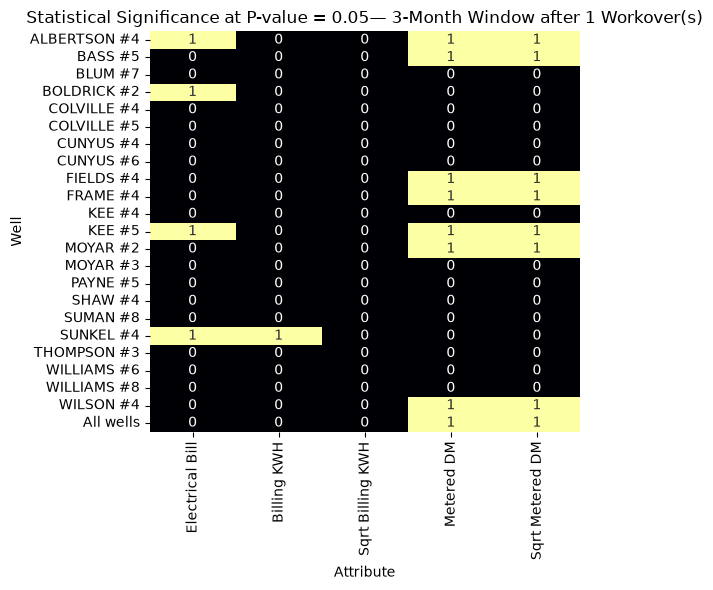

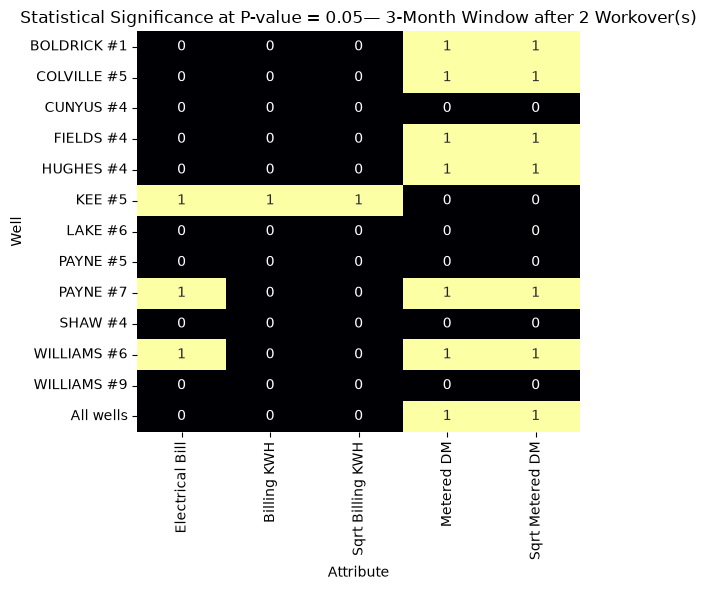

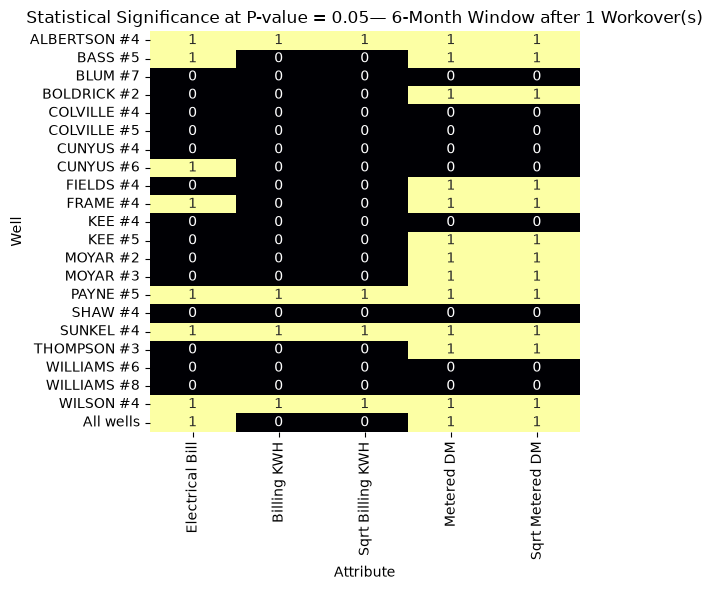

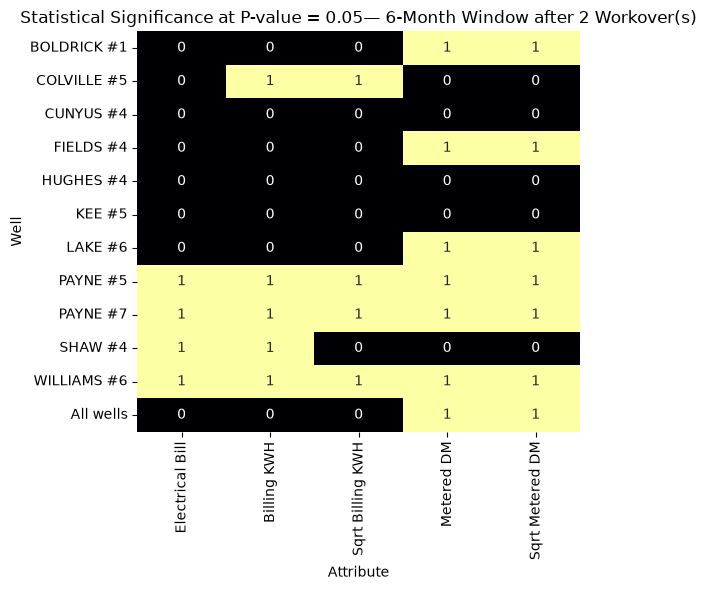

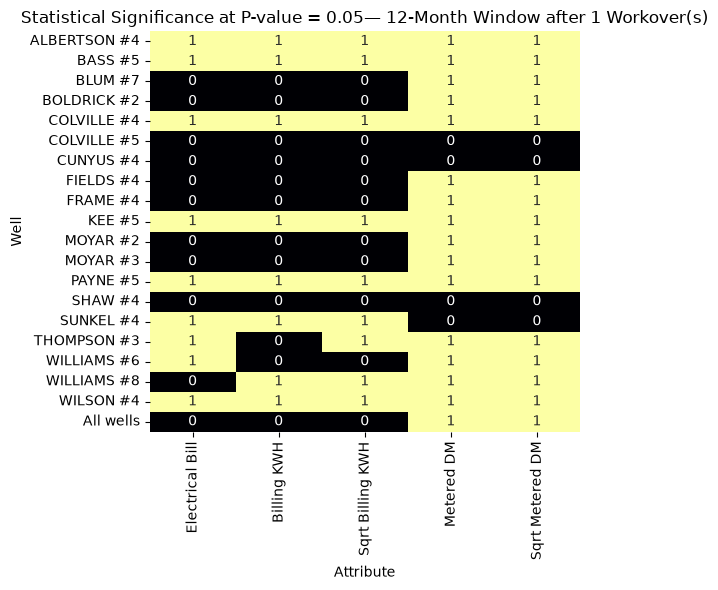

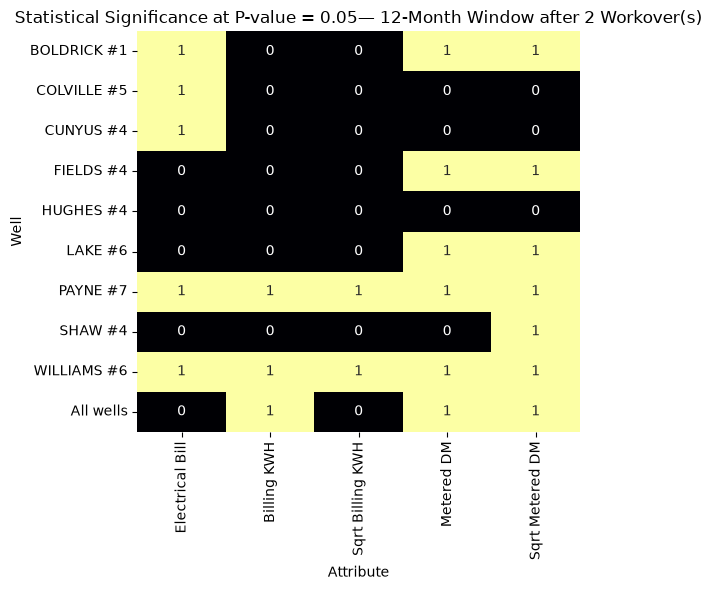

In [152]:
attribute_order = [
    "Electrical Bill", 
    "Billing KWH",
    "Sqrt Billing KWH",
    "Metered DM",
    "Sqrt Metered DM"
]



window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = ttest_df[(ttest_df["Months"] == window) & (ttest_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant 05")
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 6))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance at P-value = 0.05— {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        plt.tight_layout()
        #plt.show()

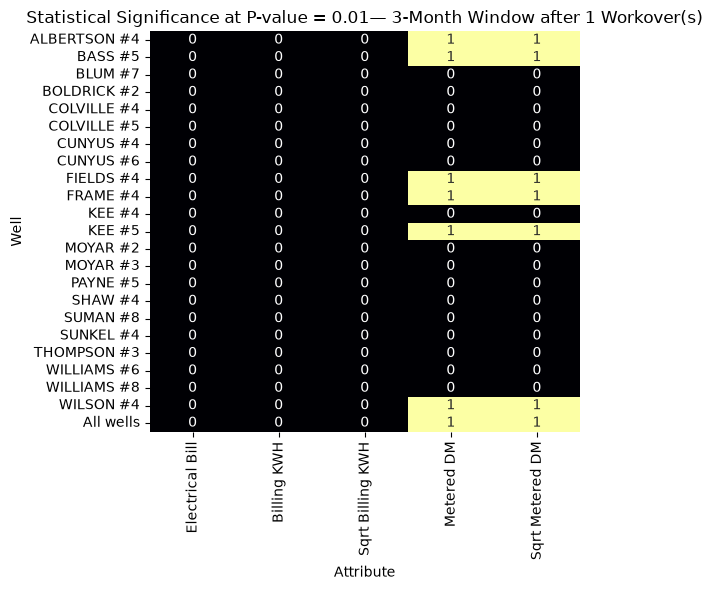

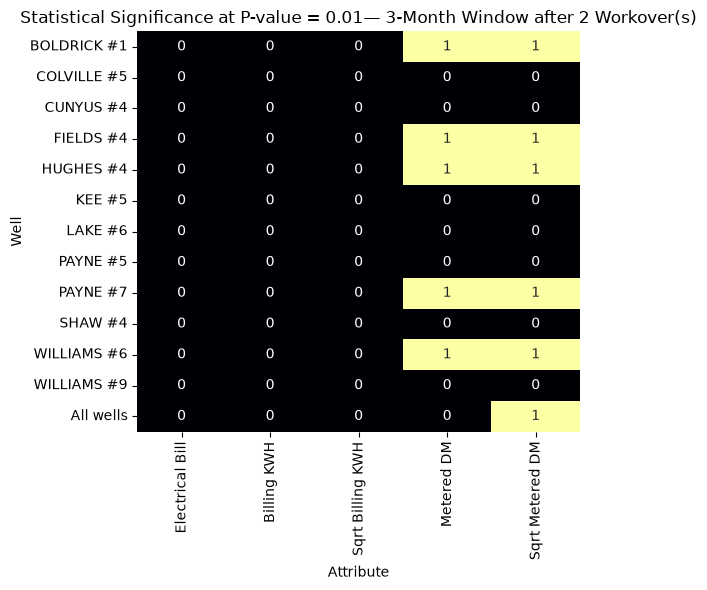

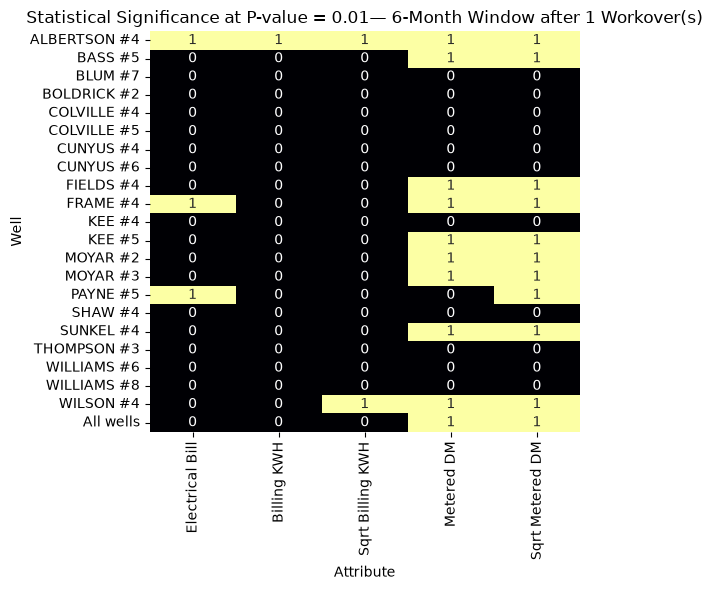

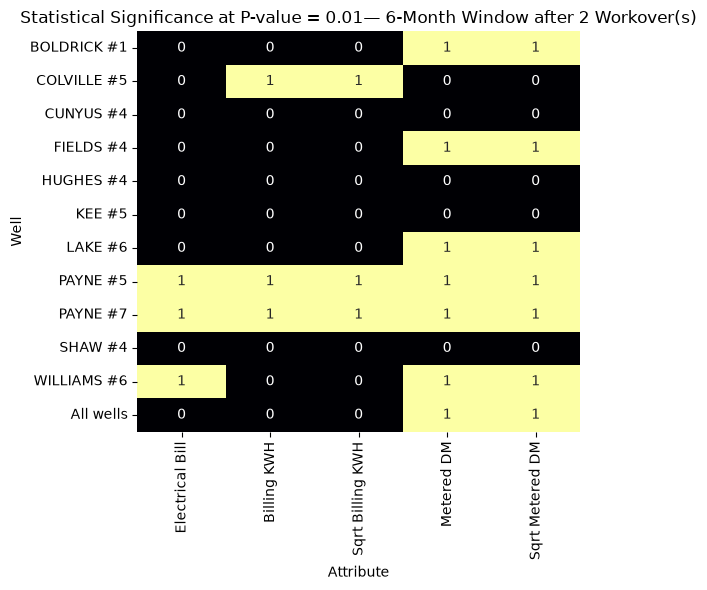

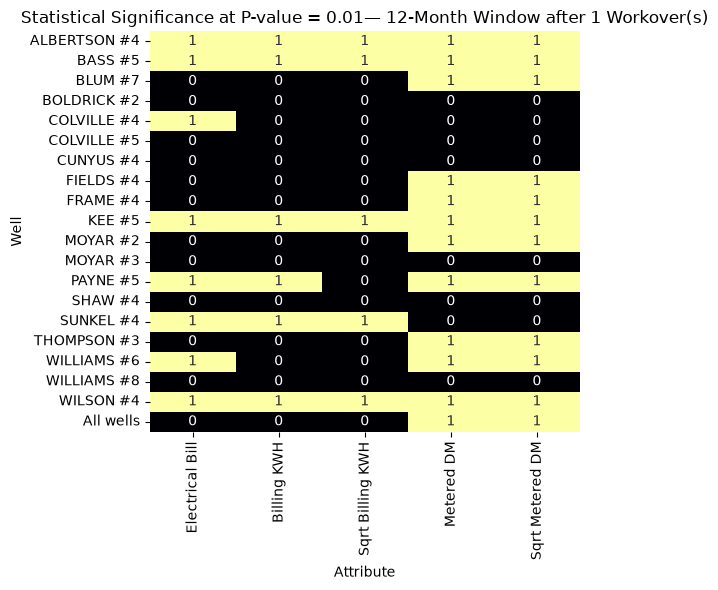

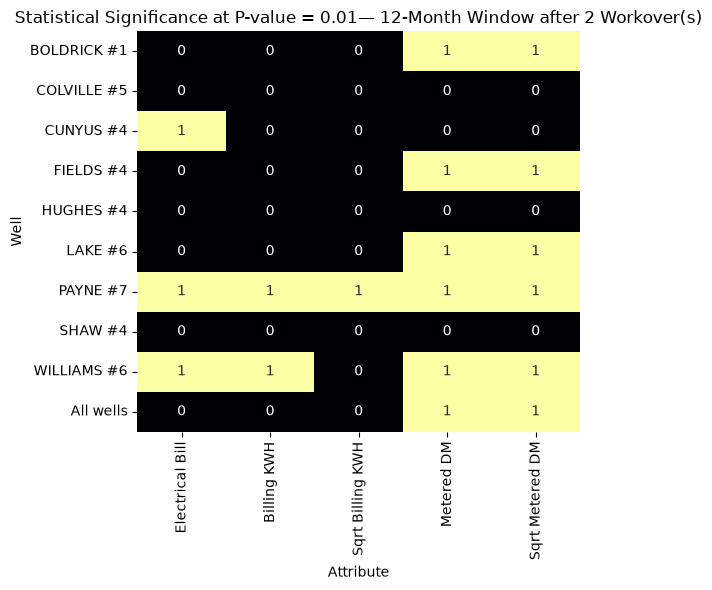

In [153]:
attribute_order = [
    "Electrical Bill", 
    "Billing KWH",
    "Sqrt Billing KWH",
    "Metered DM",
    "Sqrt Metered DM"
]



window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = ttest_df[(ttest_df["Months"] == window) & (ttest_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant 01")
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 6))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance at P-value = 0.01— {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        plt.tight_layout()
        #plt.show()